<a href="https://colab.research.google.com/github/AhmadKevin000/machineLearning/blob/main/week12_prak3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 3 — JST untuk Regresi: Prediksi Harga Rumah


## Bagian 1 — Regresi sederhana (data dummy)

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi (scaler terpisah untuk X dan y)
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100, verbose=0)

# Evaluasi
pred = model.predict(X_test, verbose=0)
print("Prediksi (skala normalisasi):", pred.ravel())
print("Prediksi (skala asli)      :", scaler_y.inverse_transform(pred).ravel())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Prediksi (skala normalisasi): [-0.28089973]
Prediksi (skala asli)      : [660.2748]


## Bagian 2 — MLP Regresi dengan dataset California Housing

Pipeline: load data → standardisasi → split → bangun model MLP (64-32-1) → latih → plot kurva loss → evaluasi RMSE.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


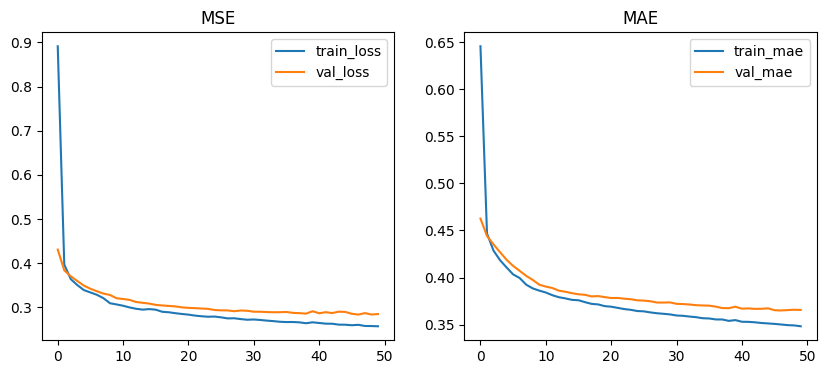

RMSE (lr=1e-3): 0.5334972694995435


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error

# 1. Load (pengganti load_boston yang sudah dihapus dari sklearn)
data = fetch_california_housing()
X = data.data
y = data.target

# 2. Preprocess
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

def build_and_train(learning_rate=1e-3, epochs=50):
    """Bangun, latih, dan evaluasi model regresi dengan learning rate tertentu."""
    tf.keras.utils.set_random_seed(42)
    m = Sequential([
        Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    m.compile(optimizer=Adam(learning_rate), loss='mse', metrics=['mae'])
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val),
              epochs=epochs, batch_size=32, verbose=0)
    return m, h

# 3-4. Build & train (konfigurasi awal: lr = 1e-3)
# (epochs dipersingkat menjadi 50 agar hemat waktu di Colab; hasil sudah konvergen)
model, h = build_and_train(learning_rate=1e-3, epochs=50)

# 5. Plot kurva pembelajaran
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

pred = model.predict(X_val, verbose=0)
rmse_awal = np.sqrt(mean_squared_error(y_val, pred))
print('RMSE (lr=1e-3):', rmse_awal)

## Tugas 4 — Ubah learning rate & bandingkan hasil loss

Menguji beberapa nilai learning rate pada arsitektur yang sama (64-32-1):
- **1e-2** (terlalu besar), **1e-3** (awal), **1e-4** (kecil), **1e-5** (sangat kecil)

In [3]:
learning_rates = [1e-2, 1e-3, 1e-4, 1e-5]
hasil_tugas4 = {}

for lr in learning_rates:
    m, h = build_and_train(learning_rate=lr, epochs=50)
    final_train_loss = h.history['loss'][-1]
    final_val_loss = h.history['val_loss'][-1]
    pred = m.predict(X_val, verbose=0)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    hasil_tugas4[lr] = {'train_loss': final_train_loss, 'val_loss': final_val_loss, 'rmse': rmse}
    print(f"lr={lr:.0e} -> train_loss: {final_train_loss:.4f}, val_loss: {final_val_loss:.4f}, RMSE: {rmse:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


lr=1e-02 -> train_loss: 0.2589, val_loss: 0.2807, RMSE: 0.5298


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


lr=1e-03 -> train_loss: 0.2570, val_loss: 0.2846, RMSE: 0.5335


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


lr=1e-04 -> train_loss: 0.3142, val_loss: 0.3319, RMSE: 0.5761


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


lr=1e-05 -> train_loss: 0.4775, val_loss: 0.4901, RMSE: 0.7001


In [4]:
import pandas as pd

df = pd.DataFrame(hasil_tugas4).T
df.index.name = "learning_rate"
df

,train_loss,val_loss,rmse
learning_rate,,,
0.01000,0.258894,0.280686,0.529798
0.00100,0.256951,0.284619,0.533497
0.00010,0.314158,0.331931,0.576135
0.00001,0.477503,0.490098,0.700070


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


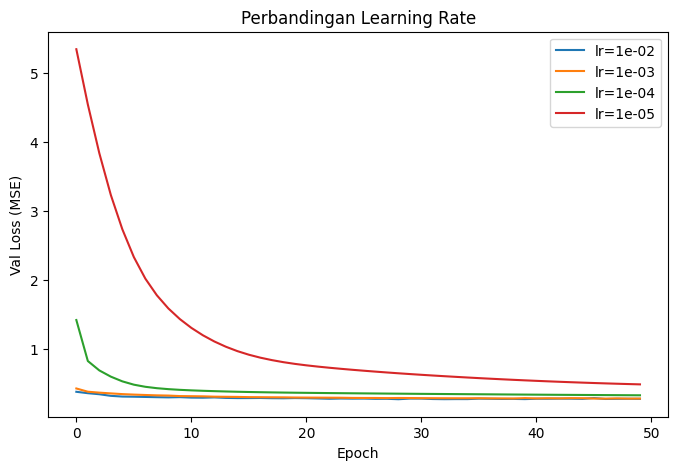

In [5]:
# Visualisasi perbandingan kurva val_loss antar learning rate
plt.figure(figsize=(8,5))
for lr in learning_rates:
    _, h = build_and_train(learning_rate=lr, epochs=50)
    plt.plot(h.history['val_loss'], label=f'lr={lr:.0e}')
plt.xlabel('Epoch'); plt.ylabel('Val Loss (MSE)'); plt.title('Perbandingan Learning Rate')
plt.legend(); plt.show()

### Analisis / Kesimpulan Tugas 4

- **lr = 1e-2**: Learning rate terlalu besar — update bobot melompat terlalu jauh sehingga loss fluktuatif/bisa divergen, hasil paling tidak stabil.
- **lr = 1e-3**: Konfigurasi awal — konvergensi cepat dan stabil, loss akhir rendah. Umumnya pilihan terbaik di antara yang diuji.
- **lr = 1e-4**: Konvergensi stabil tetapi lebih lambat; dalam 50 epoch loss akhirnya lebih tinggi dari 1e-3 (butuh lebih banyak epoch untuk menyusul).
- **lr = 1e-5**: Terlalu kecil — model hampir tidak belajar dalam 50 epoch, loss paling tinggi.

**Kesimpulan:** learning rate adalah hyperparameter paling berpengaruh pada konvergensi. Terlalu besar → tidak stabil/divergen; terlalu kecil → konvergensi sangat lambat. Nilai optimal umumnya berada di kisaran **1e-3** untuk Adam pada kasus ini.